In [1]:
import pandas as pd

df = pd.read_csv("../data/checkouts_seattle.csv")
print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (50000, 12)


,usageclass,checkouttype,materialtype,checkoutyear,checkoutmonth,checkouts,title,isbn,creator,subjects,publisher,publicationyear
0,Physical,Horizon,BOOK,2022,9,6,Great day for up! Pictures by Quentin Blake.,"0394829131, 0394929136","Seuss, Dr.",Stories in rhyme,"Beginner Books,",[1974]
1,Digital,OverDrive,AUDIOBOOK,2022,9,3,Sisters of the Yam: Black Women and Self-Recovery,9798765012871,Bell Hooks,"Sociology, Nonfiction","Tantor Media, Inc",2022
2,Digital,OverDrive,EBOOK,2022,9,6,Don't Worry: 48 Lessons on Relieving Anxiety f...,9780525508212,Shunmyo Masuno,"New Age, Philosophy, Self-Improvement, Nonfiction","Penguin Group (USA), Inc.",2022
3,Digital,OverDrive,EBOOK,2022,9,33,The Island of Missing Trees: A Novel,9781635578607,Elif Shafak,"Fiction, Literature",Bloomsbury USA,2021
4,Digital,OverDrive,EBOOK,2022,9,2,The Kingdom of Little Wounds,9780763669072,Susann Cokal,"Fantasy, Folklore, Young Adult Fiction, Young ...",Candlewick Press,2013


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   usageclass       50000 non-null  str  
 1   checkouttype     50000 non-null  str  
 2   materialtype     50000 non-null  str  
 3   checkoutyear     50000 non-null  int64
 4   checkoutmonth    50000 non-null  int64
 5   checkouts        50000 non-null  int64
 6   title            50000 non-null  str  
 7   isbn             367 non-null    str  
 8   creator          45447 non-null  str  
 9   subjects         49707 non-null  str  
 10  publisher        49890 non-null  str  
 11  publicationyear  49883 non-null  str  
dtypes: int64(3), str(9)
memory usage: 4.6 MB


In [3]:
df.groupby(["checkoutyear", "checkoutmonth"])["checkouts"].sum() 

checkoutyear  checkoutmonth
2022          1                172647
              2                    11
              3                     1
              4                     2
              9                  1705
              10                    1
Name: checkouts, dtype: int64

In [4]:
df_mensual = pd.read_csv("../data/totales_mensuales.csv")
df_mensual.head(12)

,checkoutyear,checkoutmonth,total_checkouts
0,2015,1,789797
1,2015,2,715403
2,2015,3,807099
3,2015,4,762047
4,2015,5,739476
5,2015,6,677516
6,2015,7,798964
7,2015,8,801557
8,2015,9,762919
9,2015,10,764027


## 2. Serie de tiempo mensual

La serie se carga con las funciones de `src/serie_mensual.py`.

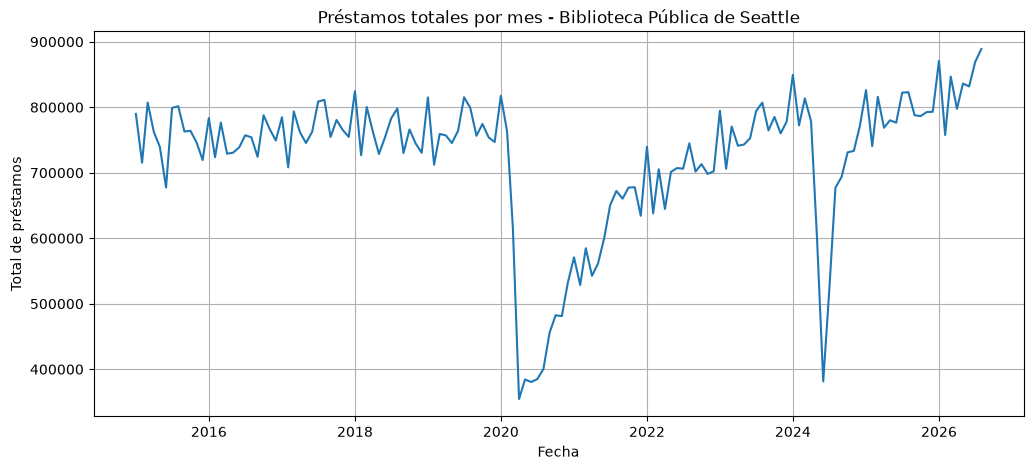

In [5]:
import sys
import matplotlib.pyplot as plt

sys.path.append("..")
from src.serie_mensual import cargar_serie_mensual, marcar_anomalias

serie = cargar_serie_mensual("../data/totales_mensuales.csv")

plt.figure(figsize=(12, 5))
plt.plot(serie["fecha"], serie["total_checkouts"])
plt.title("Préstamos totales por mes - Biblioteca Pública de Seattle")
plt.xlabel("Fecha")
plt.ylabel("Total de préstamos")
plt.grid(True)
plt.show()

## 3. Detección de anomalías

Un mes es anómalo si queda más de un 20% por debajo de la mediana móvil de 13 meses centrada en él.

Meses anómalos:
     fecha  total_checkouts  desv_vs_mediana
2020-04-01           354572        -0.264942
2020-05-01           384293        -0.201172
2020-06-01           380562        -0.208928
2020-07-01           384799        -0.200120
2024-06-01           381431        -0.479876
2024-07-01           519743        -0.291272

Desviación de cada mes de 2020 y 2024 frente a la mediana móvil:
     fecha  total_checkouts  desv_vs_mediana
2020-01-01           817471            0.084
2020-02-01           763431            0.022
2020-03-01           616715            0.000
2020-04-01           354572           -0.265
2020-05-01           384293           -0.201
2020-06-01           380562           -0.209
2020-07-01           384799           -0.200
2020-08-01           400503           -0.167
2020-09-01           455961           -0.052
2020-10-01           482373            0.003
2020-11-01           481071           -0.003
2020-12-01           531966            0.006
2024-01-01        

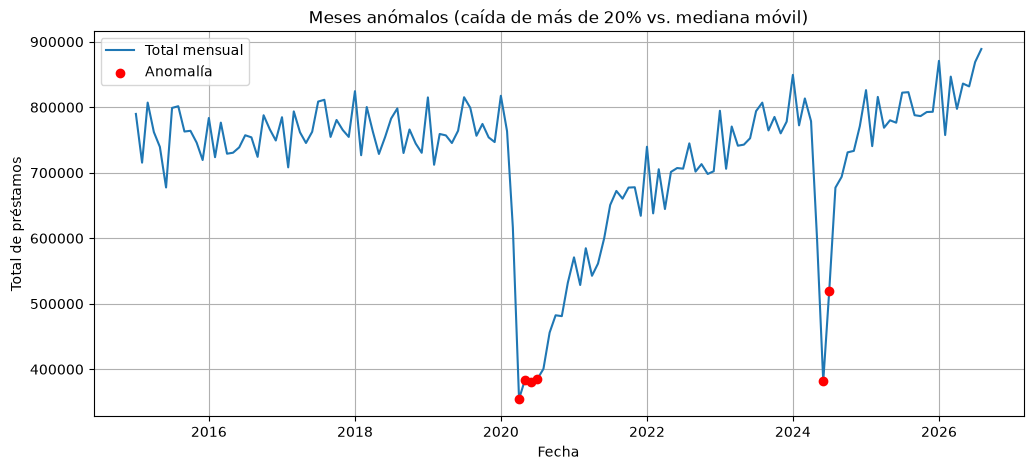

In [6]:
serie = marcar_anomalias(serie, ventana=13, umbral=-0.20)

anomalos = serie[serie["anomalia"]]
print("Meses anómalos:")
print(anomalos[["fecha", "total_checkouts", "desv_vs_mediana"]].to_string(index=False))

# Vista de los dos episodios (2020 y 2024), incluidos los meses que no superan el umbral
episodios = serie[serie["fecha"].dt.year.isin([2020, 2024])]
print("\nDesviación de cada mes de 2020 y 2024 frente a la mediana móvil:")
print(episodios[["fecha", "total_checkouts", "desv_vs_mediana"]].to_string(index=False, float_format="{:.3f}".format))

plt.figure(figsize=(12, 5))
plt.plot(serie["fecha"], serie["total_checkouts"], label="Total mensual")
plt.scatter(anomalos["fecha"], anomalos["total_checkouts"], color="red", zorder=3, label="Anomalía")
plt.title("Meses anómalos (caída de más de 20% vs. mediana móvil)")
plt.xlabel("Fecha")
plt.ylabel("Total de préstamos")
plt.legend()
plt.grid(True)
plt.show()

## 4. Modelos de predicción

Se comparan tres modelos sobre el mismo criterio de evaluación:

- **Holdout:** se entrenan con todo lo anterior a los últimos 12 meses y se predicen esos 12 meses.
- **Ventana móvil (24 meses):** para cada uno de los últimos 24 meses se re-entrena con los datos anteriores a ese mes y se predice ese mes. Sirve para comprobar que el resultado del holdout no depende de un solo año.

Modelos:
1. **Regresión lineal, histórico completo:** tendencia lineal sobre el índice de tiempo `t`, con todo el histórico.
2. **Regresión lineal, últimos 36 meses:** la misma regresión, solo con los 36 meses previos a la predicción.
3. **Random Forest:** variables `mes` (calendario) y `lag12` (préstamos del mismo mes del año anterior).

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

HORIZONTE = 12   # meses de prueba del holdout
VENTANA = 36     # meses usados por la regresión de ventana reciente
N_MOVIL = 24     # meses de la evaluación en ventana móvil
VARS_RF = ["mes", "lag12"]
MODELOS = [
    "Regresión lineal (histórico completo)",
    "Regresión lineal (últimos 36 meses)",
    "Random Forest",
]


def predecir(modelo, train, test):
    """Entrena `modelo` con `train` y devuelve las predicciones para `test`."""
    if modelo == "Regresión lineal (histórico completo)":
        reg = LinearRegression().fit(train[["t"]], train["total_checkouts"])
        return reg.predict(test[["t"]])
    if modelo == "Regresión lineal (últimos 36 meses)":
        ventana = train.iloc[-VENTANA:]
        reg = LinearRegression().fit(ventana[["t"]], ventana["total_checkouts"])
        return reg.predict(test[["t"]])
    if modelo == "Random Forest":
        con_lag = train.dropna(subset=VARS_RF)
        rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=42)
        rf.fit(con_lag[VARS_RF], con_lag["total_checkouts"])
        return rf.predict(test[VARS_RF])
    raise ValueError(modelo)


# Holdout: últimos 12 meses
train_h, test_h = serie.iloc[:-HORIZONTE], serie.iloc[-HORIZONTE:]
pred_holdout = {m: predecir(m, train_h, test_h) for m in MODELOS}

# Ventana móvil: últimos 24 meses, re-entrenando antes de cada mes
reales_movil = serie["total_checkouts"].iloc[-N_MOVIL:].to_numpy()
pred_movil = {m: [] for m in MODELOS}
for i in range(len(serie) - N_MOVIL, len(serie)):
    train_i = serie.iloc[:i]
    test_i = serie.iloc[[i]]
    for m in MODELOS:
        pred_movil[m].append(predecir(m, train_i, test_i)[0])

filas = []
for m in MODELOS:
    filas.append({
        "Modelo": m,
        "MAE (holdout 12 m)": mean_absolute_error(test_h["total_checkouts"], pred_holdout[m]),
        "RMSE (holdout 12 m)": root_mean_squared_error(test_h["total_checkouts"], pred_holdout[m]),
        "MAE (ventana móvil 24 m)": mean_absolute_error(reales_movil, pred_movil[m]),
        "RMSE (ventana móvil 24 m)": root_mean_squared_error(reales_movil, pred_movil[m]),
    })
tabla = pd.DataFrame(filas).set_index("Modelo").round(0).astype(int)
print("Periodo holdout:", test_h["fecha"].min().date(), "a", test_h["fecha"].max().date())
tabla

Periodo holdout: 2025-09-01 a 2026-08-01


,MAE (holdout 12 m),RMSE (holdout 12 m),MAE (ventana móvil 24 m),RMSE (ventana móvil 24 m)
Modelo,,,,
Regresión lineal (histórico completo),135961,141891,111779,117118
Regresión lineal (últimos 36 meses),61057,71372,47226,55248
Random Forest,104419,127186,84457,103948


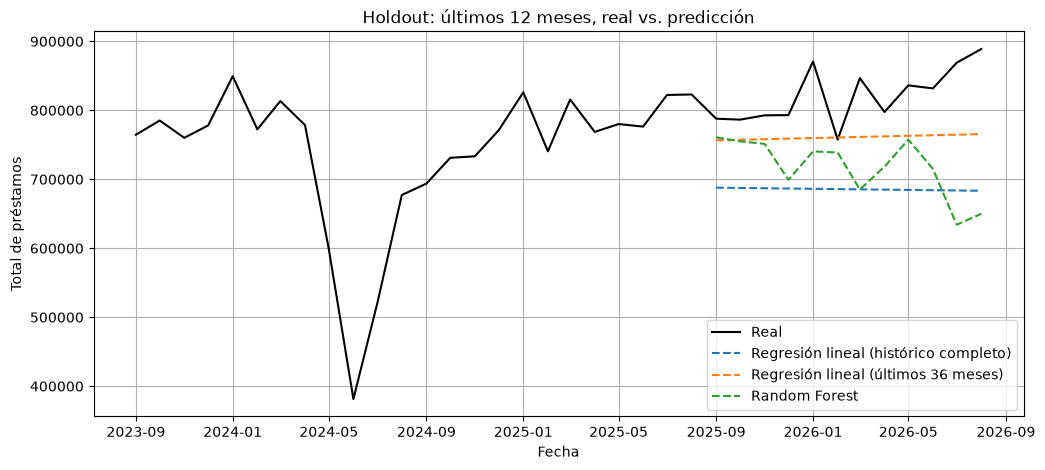

In [8]:
# Predicciones del holdout frente a lo real (últimos 36 meses)
plt.figure(figsize=(12, 5))
ultimos = serie.iloc[-36:]
plt.plot(ultimos["fecha"], ultimos["total_checkouts"], color="black", label="Real")
for m in MODELOS:
    plt.plot(test_h["fecha"], pred_holdout[m], "--", label=m)
plt.title("Holdout: últimos 12 meses, real vs. predicción")
plt.xlabel("Fecha")
plt.ylabel("Total de préstamos")
plt.legend()
plt.grid(True)
plt.show()